In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
from pathlib import Path

project_root = Path.cwd().parent

customers = pd.read_csv(
    project_root / "data/interim/customers_cleaned.csv",
    parse_dates=["signup_date"]
)

subscription_months = pd.read_csv(
    project_root / "data/interim/subscription_months_cleaned.csv"
)

print("Customers shape:", customers.shape)
print("Subscription months shape:", subscription_months.shape)

Customers shape: (1200, 12)
Subscription months shape: (19015, 15)


In [3]:
customers["cohort_month"] = (
    customers["signup_date"]
    .dt.to_period("M")
)

customer_cohorts = customers[
    ["customer_id", "cohort_month"]
].copy()

print("Total customers:", len(customer_cohorts))
print("Unique customers:", customer_cohorts["customer_id"].nunique())
print("Missing cohort months:", customer_cohorts["cohort_month"].isna().sum())

display(customer_cohorts.head())

Total customers: 1200
Unique customers: 1200
Missing cohort months: 0


,customer_id,cohort_month
0,CUS-00001,2021-09
1,CUS-00002,2023-05
2,CUS-00003,2022-09
3,CUS-00004,2021-10
4,CUS-00005,2021-05


In [4]:
subscription_months["period_month"] = pd.to_datetime(
    subscription_months["period_month"]
).dt.to_period("M")

active_customer_months = (
    subscription_months.loc[
        subscription_months["mrr_usd"] > 0,
        ["customer_id", "period_month"]
    ]
    .drop_duplicates()
    .copy()
)

print(
    "Unique active customer-month combinations:",
    len(active_customer_months)
)

print(
    "Duplicate customer-month combinations:",
    active_customer_months.duplicated(
        ["customer_id", "period_month"]
    ).sum()
)

display(active_customer_months.head())

Unique active customer-month combinations: 18647
Duplicate customer-month combinations: 0


,customer_id,period_month
0,CUS-00001,2024-01
1,CUS-00001,2024-02
2,CUS-00001,2024-03
3,CUS-00001,2024-04
4,CUS-00001,2024-05


In [5]:
cohort_activity = active_customer_months.merge(
    customer_cohorts,
    on="customer_id",
    how="left",
    validate="many_to_one"
)

print("Activity records:", len(cohort_activity))
print(
    "Missing cohort assignments:",
    cohort_activity["cohort_month"].isna().sum()
)

print(
    "Activity before signup cohort:",
    (
        cohort_activity["period_month"]
        < cohort_activity["cohort_month"]
    ).sum()
)

display(cohort_activity.head())

Activity records: 18647
Missing cohort assignments: 0
Activity before signup cohort: 0


,customer_id,period_month,cohort_month
0,CUS-00001,2024-01,2021-09
1,CUS-00001,2024-02,2021-09
2,CUS-00001,2024-03,2021-09
3,CUS-00001,2024-04,2021-09
4,CUS-00001,2024-05,2021-09


In [6]:
# Step 6.1.2 - Calculate cohort age in months

cohort_activity["cohort_age"] = (
    (cohort_activity["period_month"].dt.year -
     cohort_activity["cohort_month"].dt.year) * 12
    +
    (cohort_activity["period_month"].dt.month -
     cohort_activity["cohort_month"].dt.month)
)

print("Minimum cohort age:", cohort_activity["cohort_age"].min())
print("Maximum cohort age:", cohort_activity["cohort_age"].max())

print(
    "Negative cohort ages:",
    (cohort_activity["cohort_age"] < 0).sum()
)

display(cohort_activity.head())

Minimum cohort age: 0
Maximum cohort age: 65
Negative cohort ages: 0


,customer_id,period_month,cohort_month,cohort_age
0,CUS-00001,2024-01,2021-09,28
1,CUS-00001,2024-02,2021-09,29
2,CUS-00001,2024-03,2021-09,30
3,CUS-00001,2024-04,2021-09,31
4,CUS-00001,2024-05,2021-09,32


In [7]:
# Count all customers in each signup cohort

cohort_sizes = (
    customer_cohorts
    .groupby("cohort_month")["customer_id"]
    .nunique()
    .rename("cohort_size")
)

print("Total cohort customers:", cohort_sizes.sum())
print("Number of cohorts:", len(cohort_sizes))

display(cohort_sizes.head(10))

Total cohort customers: 1200
Number of cohorts: 66


cohort_month
2021-01    13
2021-02    10
2021-03    13
2021-04    13
2021-05    17
2021-06     9
2021-07    14
2021-08    14
2021-09    13
2021-10    15
Freq: M, Name: cohort_size, dtype: int64

In [8]:
# Count unique revenue-active customers by cohort and age

cohort_counts = (
    cohort_activity
    .groupby(["cohort_month", "cohort_age"])["customer_id"]
    .nunique()
    .unstack("cohort_age")
    .reindex(index=cohort_sizes.index)
    .sort_index(axis=1)
)

print("Cohort count matrix shape:", cohort_counts.shape)

display(cohort_counts.head(10))

Cohort count matrix shape: (66, 66)


cohort_age,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65
cohort_month,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2021-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13.0,13.0,13.0,13.0,12.0,12.0,12.0,12.0,11.0,11.0,10.0,10.0,9.0,9.0,9.0,9.0,9.0,8.0,8.0,8.0,8.0,8.0,8.0,8.0,8.0,8.0,7.0,7.0,7.0,7.0
2021-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.0,10.0,10.0,10.0,10.0,10.0,10.0,10.0,10.0,10.0,10.0,9.0,9.0,8.0,8.0,8.0,8.0,7.0,6.0,7.0,7.0,7.0,7.0,7.0,7.0,6.0,6.0,6.0,6.0,6.0,NaN
2021-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13.0,13.0,13.0,11.0,11.0,11.0,11.0,11.0,11.0,11.0,11.0,11.0,11.0,11.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,NaN,NaN
2021-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13.0,13.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,11.0,11.0,11.0,11.0,11.0,11.0,11.0,10.0,10.0,10.0,NaN,NaN,NaN
2021-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,17.0,16.0,15.0,15.0,15.0,15.0,15.0,15.0,14.0,14.0,14.0,13.0,13.0,13.0,13.0,13.0,13.0,13.0,13.0,13.0,13.0,13.0,13.0,13.0,13.0,13.0,13.0,13.0,13.0,13.0,NaN,NaN,NaN,NaN
2021-06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.0,9.0,9.0,9.0,8.0,8.0,8.0,8.0,8.0,8.0,8.0,8.0,8.0,8.0,8.0,8.0,7.0,7.0,7.0,7.0,7.0,7.0,7.0,7.0,7.0,7.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN
2021-07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,14.0,14.0,14.0,14.0,13.0,12.0,12.0,11.0,11.0,11.0,11.0,11.0,11.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,NaN,NaN,NaN,NaN,NaN,NaN
2021-08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,14.0,13.0,13.0,13.0,13.0,13.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-09,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13.0,12.0,12.0,12.0,11.0,10.0,10.0,10.0,10.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,8.0,6.0,6.0,6.0,6.0,6.0,6.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
# Divide active customers by original cohort size

cohort_retention = (
    cohort_counts
    .div(cohort_sizes, axis=0)
    .mul(100)
    .round(2)
)

cohort_retention.index.name = "cohort_month"

print("Cohort retention matrix:")
display(cohort_retention.head(10))

Cohort retention matrix:


cohort_age,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65
cohort_month,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2021-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.00,100.00,100.00,100.00,92.31,92.31,92.31,92.31,84.62,84.62,76.92,76.92,69.23,69.23,69.23,69.23,69.23,61.54,61.54,61.54,61.54,61.54,61.54,61.54,61.54,61.54,53.85,53.85,53.85,53.85
2021-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,90.00,90.00,80.00,80.00,80.00,80.00,70.00,60.00,70.00,70.00,70.00,70.00,70.00,70.00,60.00,60.00,60.00,60.00,60.00,NaN
2021-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.00,100.00,100.00,84.62,84.62,84.62,84.62,84.62,84.62,84.62,84.62,84.62,84.62,84.62,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,NaN,NaN
2021-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.00,100.00,92.31,92.31,92.31,92.31,92.31,92.31,92.31,92.31,92.31,92.31,92.31,92.31,92.31,92.31,92.31,92.31,92.31,92.31,84.62,84.62,84.62,84.62,84.62,84.62,84.62,76.92,76.92,76.92,NaN,NaN,NaN
2021-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.00,94.12,88.24,88.24,88.24,88.24,88.24,88.24,82.35,82.35,82.35,76.47,76.47,76.47,76.47,76.47,76.47,76.47,76.47,76.47,76.47,76.47,76.47,76.47,76.47,76.47,76.47,76.47,76.47,76.47,NaN,NaN,NaN,NaN
2021-06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.00,100.00,100.00,100.00,88.89,88.89,88.89,88.89,88.89,88.89,88.89,88.89,88.89,88.89,88.89,88.89,77.78,77.78,77.78,77.78,77.78,77.78,77.78,77.78,77.78,77.78,77.78,77.78,77.78,77.78,NaN,NaN,NaN,NaN,NaN
2021-07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.00,100.00,100.00,100.00,92.86,85.71,85.71,78.57,78.57,78.57,78.57,78.57,78.57,64.29,64.29,64.29,64.29,64.29,64.29,64.29,64.29,64.29,64.29,64.29,64.29,64.29,64.29,64.29,64.29,64.29,NaN,NaN,NaN,NaN,NaN,NaN
2021-08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.00,92.86,92.86,92.86,92.86,92.86,85.71,85.71,85.71,85.71,85.71,85.71,85.71,85.71,85.71,85.71,85.71,85.71,85.71,85.71,85.71,85.71,85.71,85.71,85.71,85.71,85.71,85.71,85.71,85.71,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-09,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.0,92.31,92.31,92.31,84.62,76.92,76.92,76.92,76.92,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,61.54,46.15,46.15,46.15,46.15,46.15,46.15,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
# Validation checks

negative_values = (
    (cohort_retention < 0).sum().sum()
)

above_100_values = (
    (cohort_retention > 100).sum().sum()
)

counts_above_cohort_size = (
    cohort_counts.gt(cohort_sizes, axis=0)
    .sum().sum()
)

print("Negative retention values:", negative_values)
print("Retention values above 100%:", above_100_values)
print("Active counts above cohort size:", counts_above_cohort_size)

assert negative_values == 0
assert above_100_values == 0
assert counts_above_cohort_size == 0

print("Cohort retention validation PASSED.")

Negative retention values: 0
Retention values above 100%: 0
Active counts above cohort size: 0
Cohort retention validation PASSED.


In [11]:
# Identify the final month available in the dataset

last_observed_month = subscription_months["period_month"].max()

for age in cohort_retention.columns:
    observable = (
        cohort_retention.index + int(age)
        <= last_observed_month
    )

    cohort_retention.loc[~observable, age] = np.nan

print("Last observed month:", last_observed_month)

display(cohort_retention.head(10))

Last observed month: 2026-06


cohort_age,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65
cohort_month,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2021-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.00,100.00,100.00,100.00,92.31,92.31,92.31,92.31,84.62,84.62,76.92,76.92,69.23,69.23,69.23,69.23,69.23,61.54,61.54,61.54,61.54,61.54,61.54,61.54,61.54,61.54,53.85,53.85,53.85,53.85
2021-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,90.00,90.00,80.00,80.00,80.00,80.00,70.00,60.00,70.00,70.00,70.00,70.00,70.00,70.00,60.00,60.00,60.00,60.00,60.00,NaN
2021-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.00,100.00,100.00,84.62,84.62,84.62,84.62,84.62,84.62,84.62,84.62,84.62,84.62,84.62,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,NaN,NaN
2021-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.00,100.00,92.31,92.31,92.31,92.31,92.31,92.31,92.31,92.31,92.31,92.31,92.31,92.31,92.31,92.31,92.31,92.31,92.31,92.31,84.62,84.62,84.62,84.62,84.62,84.62,84.62,76.92,76.92,76.92,NaN,NaN,NaN
2021-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.00,94.12,88.24,88.24,88.24,88.24,88.24,88.24,82.35,82.35,82.35,76.47,76.47,76.47,76.47,76.47,76.47,76.47,76.47,76.47,76.47,76.47,76.47,76.47,76.47,76.47,76.47,76.47,76.47,76.47,NaN,NaN,NaN,NaN
2021-06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.00,100.00,100.00,100.00,88.89,88.89,88.89,88.89,88.89,88.89,88.89,88.89,88.89,88.89,88.89,88.89,77.78,77.78,77.78,77.78,77.78,77.78,77.78,77.78,77.78,77.78,77.78,77.78,77.78,77.78,NaN,NaN,NaN,NaN,NaN
2021-07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.00,100.00,100.00,100.00,92.86,85.71,85.71,78.57,78.57,78.57,78.57,78.57,78.57,64.29,64.29,64.29,64.29,64.29,64.29,64.29,64.29,64.29,64.29,64.29,64.29,64.29,64.29,64.29,64.29,64.29,NaN,NaN,NaN,NaN,NaN,NaN
2021-08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.00,92.86,92.86,92.86,92.86,92.86,85.71,85.71,85.71,85.71,85.71,85.71,85.71,85.71,85.71,85.71,85.71,85.71,85.71,85.71,85.71,85.71,85.71,85.71,85.71,85.71,85.71,85.71,85.71,85.71,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-09,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.0,92.31,92.31,92.31,84.62,76.92,76.92,76.92,76.92,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,61.54,46.15,46.15,46.15,46.15,46.15,46.15,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
# Fill observed missing counts with zero,
# while keeping future months as NaN

for age in cohort_retention.columns:
    observable = (
        cohort_retention.index + int(age)
        <= last_observed_month
    )

    cohort_retention.loc[observable, age] = (
        cohort_retention.loc[observable, age]
        .fillna(0)
    )

print("Final customer cohort retention matrix:")
display(cohort_retention.head(10))

Final customer cohort retention matrix:


cohort_age,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65
cohort_month,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2021-01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,100.00,100.00,100.00,100.00,92.31,92.31,92.31,92.31,84.62,84.62,76.92,76.92,69.23,69.23,69.23,69.23,69.23,61.54,61.54,61.54,61.54,61.54,61.54,61.54,61.54,61.54,53.85,53.85,53.85,53.85
2021-02,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.00,0.00,0.00,0.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,90.00,90.00,80.00,80.00,80.00,80.00,70.00,60.00,70.00,70.00,70.00,70.00,70.00,70.00,60.00,60.00,60.00,60.00,60.00,NaN
2021-03,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.00,0.00,0.00,100.00,100.00,100.00,84.62,84.62,84.62,84.62,84.62,84.62,84.62,84.62,84.62,84.62,84.62,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,NaN,NaN
2021-04,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.00,0.00,100.00,100.00,92.31,92.31,92.31,92.31,92.31,92.31,92.31,92.31,92.31,92.31,92.31,92.31,92.31,92.31,92.31,92.31,92.31,92.31,84.62,84.62,84.62,84.62,84.62,84.62,84.62,76.92,76.92,76.92,NaN,NaN,NaN
2021-05,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.00,100.00,94.12,88.24,88.24,88.24,88.24,88.24,88.24,82.35,82.35,82.35,76.47,76.47,76.47,76.47,76.47,76.47,76.47,76.47,76.47,76.47,76.47,76.47,76.47,76.47,76.47,76.47,76.47,76.47,76.47,NaN,NaN,NaN,NaN
2021-06,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.00,100.00,100.00,100.00,100.00,88.89,88.89,88.89,88.89,88.89,88.89,88.89,88.89,88.89,88.89,88.89,88.89,77.78,77.78,77.78,77.78,77.78,77.78,77.78,77.78,77.78,77.78,77.78,77.78,77.78,77.78,NaN,NaN,NaN,NaN,NaN
2021-07,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,100.00,100.00,100.00,100.00,92.86,85.71,85.71,78.57,78.57,78.57,78.57,78.57,78.57,64.29,64.29,64.29,64.29,64.29,64.29,64.29,64.29,64.29,64.29,64.29,64.29,64.29,64.29,64.29,64.29,64.29,NaN,NaN,NaN,NaN,NaN,NaN
2021-08,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.00,92.86,92.86,92.86,92.86,92.86,85.71,85.71,85.71,85.71,85.71,85.71,85.71,85.71,85.71,85.71,85.71,85.71,85.71,85.71,85.71,85.71,85.71,85.71,85.71,85.71,85.71,85.71,85.71,85.71,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-09,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,92.31,92.31,92.31,84.62,76.92,76.92,76.92,76.92,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,61.54,46.15,46.15,46.15,46.15,46.15,46.15,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [13]:
import seaborn as sns

sns.set_theme(style="white")

print("Seaborn imported successfully.")

Seaborn imported successfully.


In [14]:
# Step 6.1.3 - Prepare heatmap data

heatmap_data = cohort_retention.copy()

# Convert signup cohort to readable labels
heatmap_data.index = heatmap_data.index.strftime("%b %Y")

# Rename cohort ages
heatmap_data.columns = [
    f"Month {int(age)}"
    for age in heatmap_data.columns
]

print("Heatmap shape:", heatmap_data.shape)

display(heatmap_data.head())

Heatmap shape: (66, 66)


,Month 0,Month 1,Month 2,Month 3,Month 4,Month 5,Month 6,Month 7,Month 8,Month 9,Month 10,Month 11,Month 12,Month 13,Month 14,Month 15,Month 16,Month 17,Month 18,Month 19,Month 20,Month 21,Month 22,Month 23,Month 24,Month 25,Month 26,Month 27,Month 28,Month 29,Month 30,Month 31,Month 32,Month 33,Month 34,Month 35,Month 36,Month 37,Month 38,Month 39,Month 40,Month 41,Month 42,Month 43,Month 44,Month 45,Month 46,Month 47,Month 48,Month 49,Month 50,Month 51,Month 52,Month 53,Month 54,Month 55,Month 56,Month 57,Month 58,Month 59,Month 60,Month 61,Month 62,Month 63,Month 64,Month 65
cohort_month,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Jan 2021,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.00,100.00,100.00,100.00,100.00,92.31,92.31,92.31,92.31,84.62,84.62,76.92,76.92,69.23,69.23,69.23,69.23,69.23,61.54,61.54,61.54,61.54,61.54,61.54,61.54,61.54,61.54,53.85,53.85,53.85,53.85
Feb 2021,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,90.00,90.00,80.00,80.00,80.00,80.00,70.00,60.00,70.00,70.00,70.00,70.00,70.00,70.00,60.00,60.00,60.00,60.00,60.00,NaN
Mar 2021,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,100.00,100.00,100.00,84.62,84.62,84.62,84.62,84.62,84.62,84.62,84.62,84.62,84.62,84.62,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,69.23,NaN,NaN
Apr 2021,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.00,100.00,92.31,92.31,92.31,92.31,92.31,92.31,92.31,92.31,92.31,92.31,92.31,92.31,92.31,92.31,92.31,92.31,92.31,92.31,84.62,84.62,84.62,84.62,84.62,84.62,84.62,76.92,76.92,76.92,NaN,NaN,NaN
May 2021,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,94.12,88.24,88.24,88.24,88.24,88.24,88.24,82.35,82.35,82.35,76.47,76.47,76.47,76.47,76.47,76.47,76.47,76.47,76.47,76.47,76.47,76.47,76.47,76.47,76.47,76.47,76.47,76.47,76.47,NaN,NaN,NaN,NaN


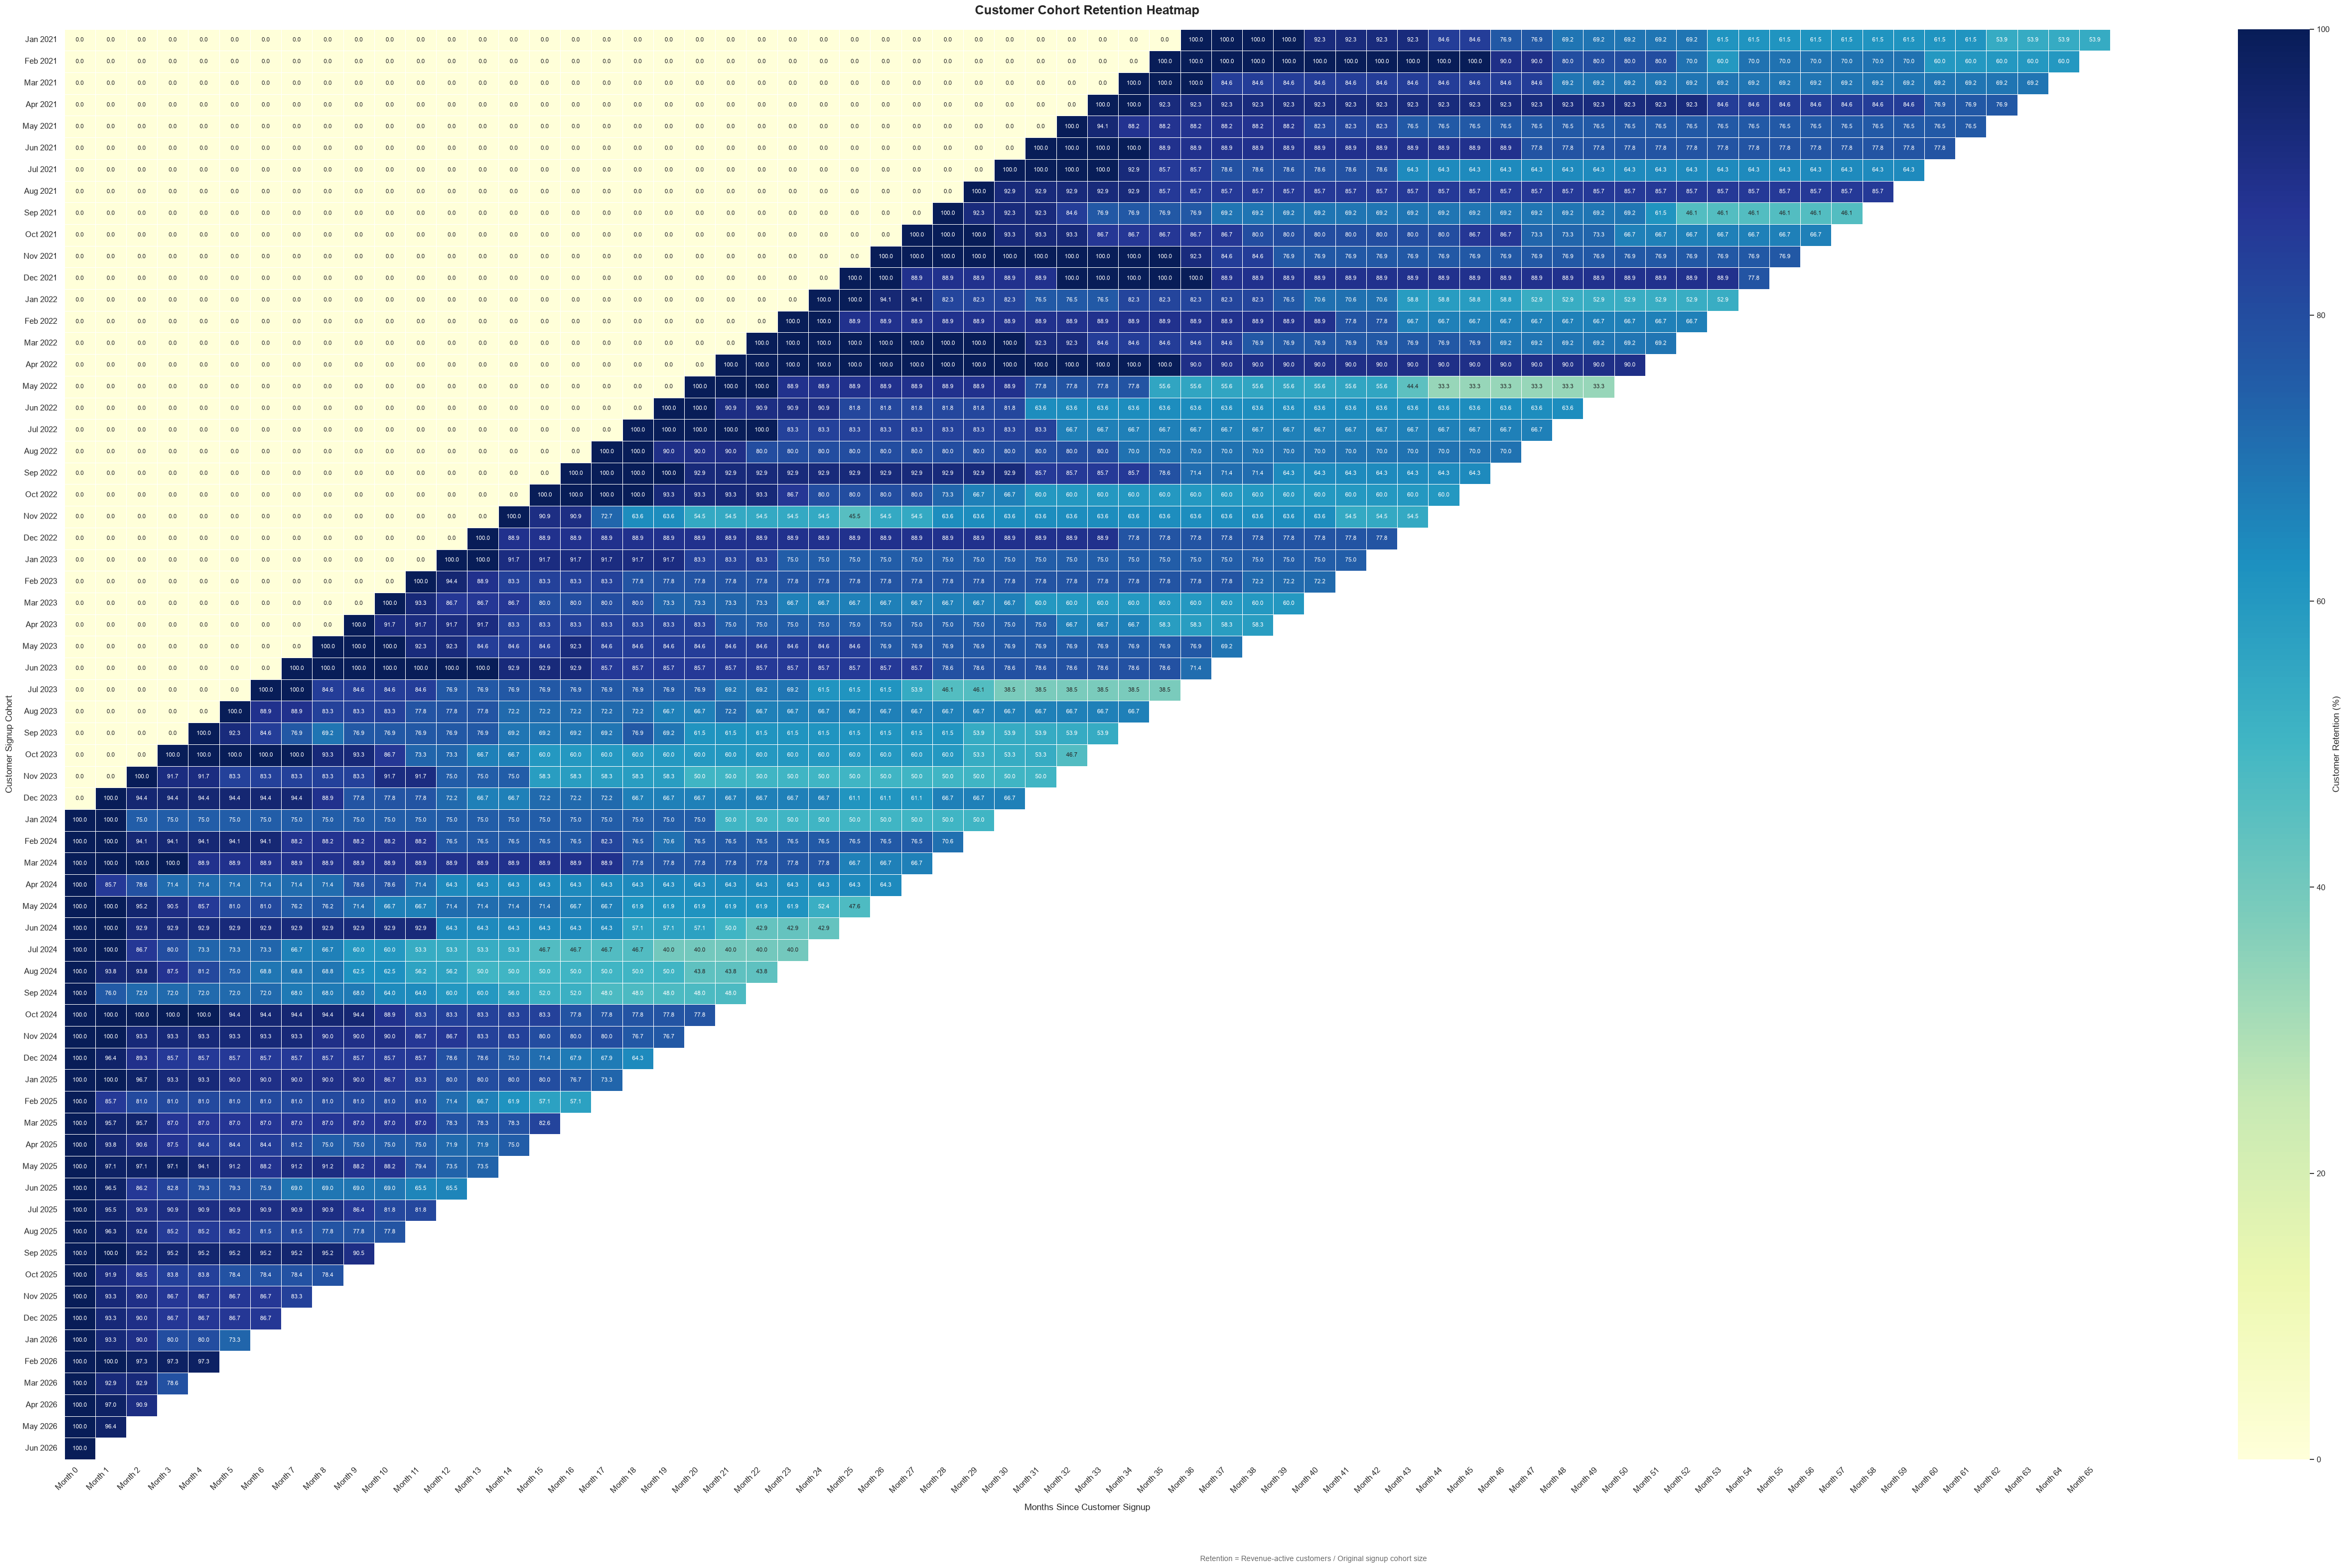

In [15]:
# Create customer cohort retention heatmap

fig_width = max(12, len(heatmap_data.columns) * 0.75)
fig_height = max(6, len(heatmap_data.index) * 0.45)

fig, ax = plt.subplots(
    figsize=(fig_width, fig_height)
)

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    vmin=0,
    vmax=100,
    mask=heatmap_data.isna(),
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Customer Retention (%)"},
    annot_kws={"fontsize": 8},
    ax=ax
)

ax.set_title(
    "Customer Cohort Retention Heatmap",
    fontsize=17,
    fontweight="bold",
    pad=20
)

ax.set_xlabel(
    "Months Since Customer Signup",
    fontsize=12,
    labelpad=12
)

ax.set_ylabel(
    "Customer Signup Cohort",
    fontsize=12,
    labelpad=12
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

fig.text(
    0.5,
    0.01,
    "Retention = Revenue-active customers / Original signup cohort size",
    ha="center",
    fontsize=10,
    color="dimgray"
)

plt.tight_layout(rect=[0, 0.035, 1, 1])
plt.show()

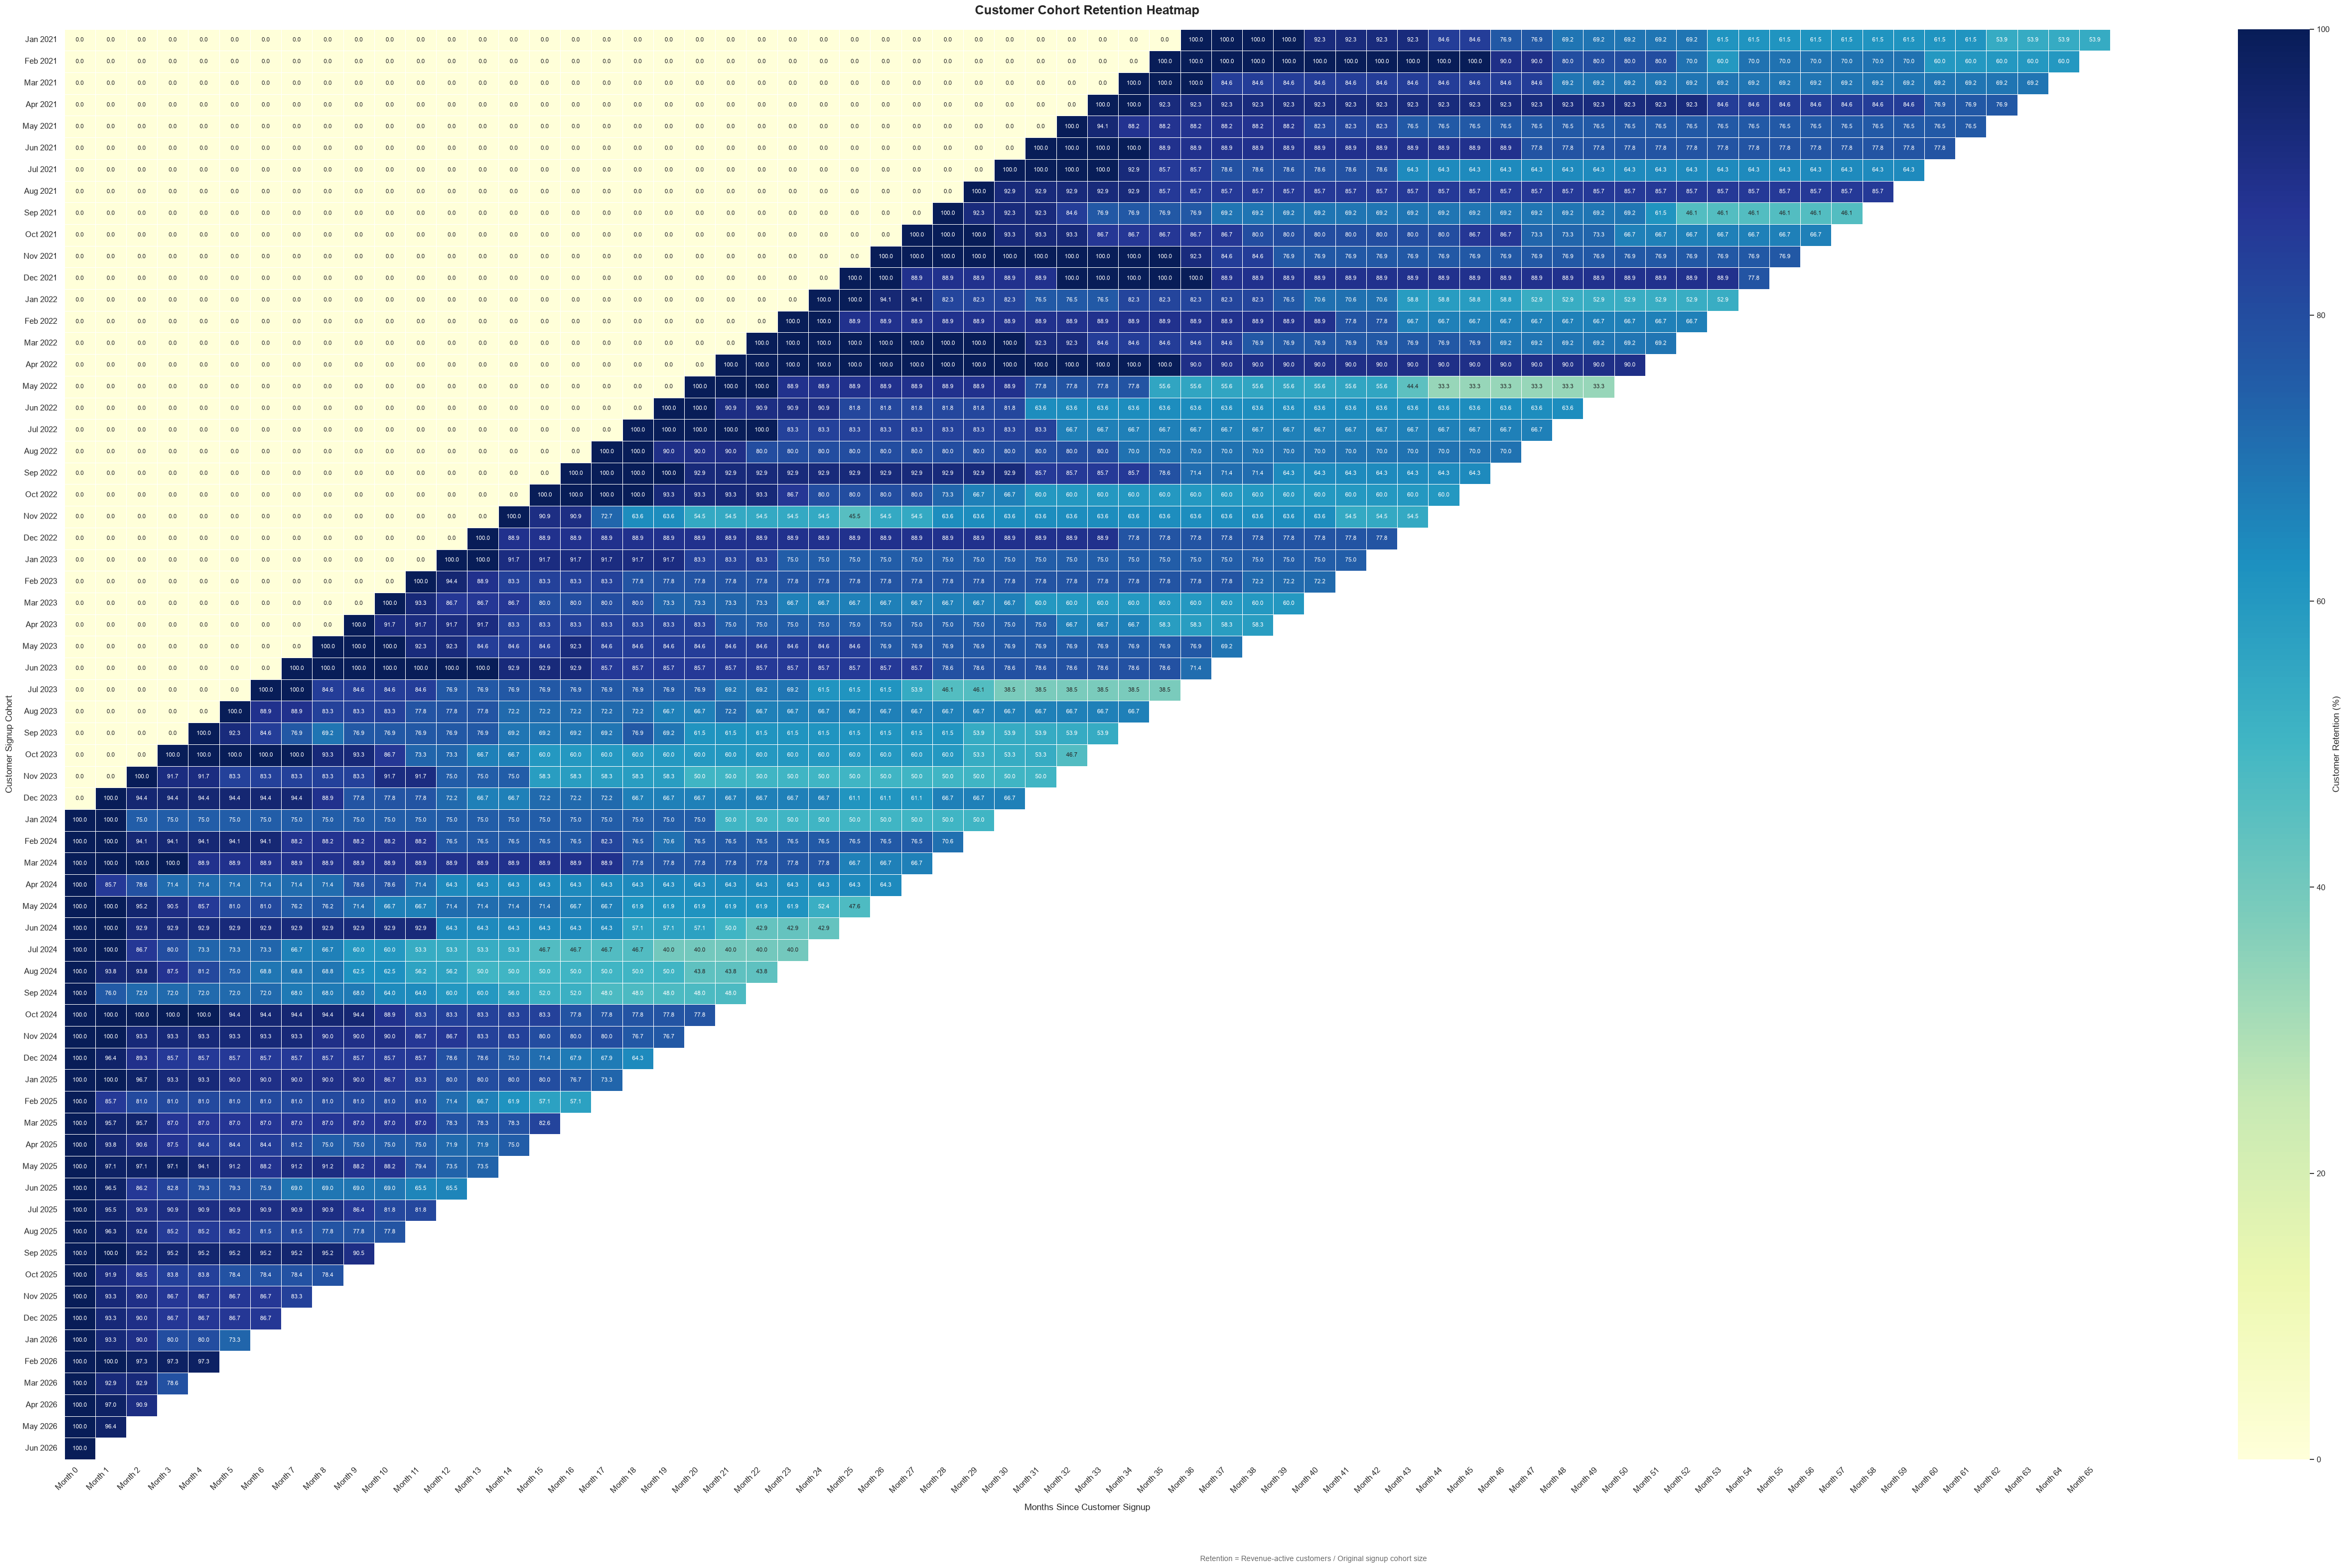

In [16]:
# Create customer cohort retention heatmap

fig_width = max(12, len(heatmap_data.columns) * 0.75)
fig_height = max(6, len(heatmap_data.index) * 0.45)

fig, ax = plt.subplots(
    figsize=(fig_width, fig_height)
)

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    vmin=0,
    vmax=100,
    mask=heatmap_data.isna(),
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Customer Retention (%)"},
    annot_kws={"fontsize": 8},
    ax=ax
)

ax.set_title(
    "Customer Cohort Retention Heatmap",
    fontsize=17,
    fontweight="bold",
    pad=20
)

ax.set_xlabel(
    "Months Since Customer Signup",
    fontsize=12,
    labelpad=12
)

ax.set_ylabel(
    "Customer Signup Cohort",
    fontsize=12,
    labelpad=12
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

fig.text(
    0.5,
    0.01,
    "Retention = Revenue-active customers / Original signup cohort size",
    ha="center",
    fontsize=10,
    color="dimgray"
)

plt.tight_layout(rect=[0, 0.035, 1, 1])
plt.show()

In [17]:
from pathlib import Path

output_path = (
    Path.cwd().parent
    / "reports"
    / "figures"
    / "customer_cohort_retention_heatmap.png"
)

output_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

print("Heatmap saved successfully.")
print("File:", output_path)
print("File exists:", output_path.exists())

Heatmap saved successfully.
File: c:\Users\ANKIT TRIPATHI\Desktop\SaaS-Revenue-Subscription-Analytics\reports\figures\customer_cohort_retention_heatmap.png
File exists: True


In [18]:
# Step 6.1.4 - Overall weighted cohort retention

overall_retention = {}

for age in cohort_counts.columns:

    # Include only cohorts whose age is observable
    observable = (
        cohort_sizes.index + int(age)
        <= last_observed_month
    )

    eligible_cohorts = cohort_sizes.index[observable]

    eligible_customers = cohort_sizes.loc[
        eligible_cohorts
    ].sum()

    active_customers = (
        cohort_counts.loc[eligible_cohorts, age]
        .fillna(0)
        .sum()
    )

    overall_retention[int(age)] = (
        active_customers / eligible_customers * 100
        if eligible_customers > 0
        else np.nan
    )

overall_retention = pd.Series(
    overall_retention,
    name="retention_pct"
).round(2)

display(overall_retention.head(7))

0    61.67
1    59.16
2    56.65
3    54.90
4    54.84
5    54.00
6    54.02
Name: retention_pct, dtype: float64

In [19]:
# Compare cohorts using Month 1 retention

month_1_cohorts = cohort_retention[
    1
].dropna()

if month_1_cohorts.empty:
    print("No cohorts have observable Month 1 retention.")
else:
    best_cohort = month_1_cohorts.idxmax()
    worst_cohort = month_1_cohorts.idxmin()

    print(
        "Best Month 1 cohort:",
        best_cohort,
        f"({month_1_cohorts.max():.2f}%)"
    )

    print(
        "Worst Month 1 cohort:",
        worst_cohort,
        f"({month_1_cohorts.min():.2f}%)"
    )

Best Month 1 cohort: 2023-12 (100.00%)
Worst Month 1 cohort: 2021-01 (0.00%)


In [20]:
# Retention comparison across cohort ages

month_0 = overall_retention.get(0, np.nan)
month_1 = overall_retention.get(1, np.nan)
month_3 = overall_retention.get(3, np.nan)

print(f"Month 0 activation: {month_0:.2f}%")
print(f"Month 1 retention: {month_1:.2f}%")
print(f"Month 3 retention: {month_3:.2f}%")

if pd.notna(month_0) and pd.notna(month_3):
    change_pp = month_3 - month_0

    print(
        "Month 0 to Month 3 change:",
        f"{change_pp:+.2f} percentage points"
    )

Month 0 activation: 61.67%
Month 1 retention: 59.16%
Month 3 retention: 54.90%
Month 0 to Month 3 change: -6.77 percentage points


In [21]:
# Compare Month 0 and Month 3
# using the same eligible signup cohorts

if 0 in cohort_counts.columns and 3 in cohort_counts.columns:

    eligible = (
        cohort_sizes.index + 3 <= last_observed_month
    )

    eligible_cohorts = cohort_sizes.index[eligible]

    total_eligible = cohort_sizes.loc[
        eligible_cohorts
    ].sum()

    if total_eligible > 0:

        m0_count = (
            cohort_counts.loc[eligible_cohorts, 0]
            .fillna(0)
            .sum()
        )

        m3_count = (
            cohort_counts.loc[eligible_cohorts, 3]
            .fillna(0)
            .sum()
        )

        m0_rate = m0_count / total_eligible * 100
        m3_rate = m3_count / total_eligible * 100

        print(f"Eligible cohort customers: {total_eligible}")
        print(f"Month 0 activation: {m0_rate:.2f}%")
        print(f"Month 3 retention: {m3_rate:.2f}%")
        print(
            "Retention change:",
            f"{m3_rate - m0_rate:+.2f} percentage points"
        )
    else:
        print("No cohorts eligible for Month 3 comparison.")

else:
    print("Month 0 or Month 3 data unavailable.")

Eligible cohort customers: 1102
Month 0 activation: 58.26%
Month 3 retention: 54.90%
Retention change: -3.36 percentage points
